In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("/content/ShopSmart_synthetic_cleaned (1).csv")

In [3]:
df.head()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent,Amount_Spent_Range,Age_Group
0,41,946794.0,17.0,10,Bronze,Beauty,Tier 1,Yes,21323.29,Very High,40-50
1,58,802984.0,8.0,7,Bronze,Fashion,Tier 2,No,16160.83,Low,50-70
2,57,180000.0,9.0,5,Silver,Home,Tier 2,No,10315.23,Very Low,50-70
3,34,638755.0,14.0,5,Silver,Electronics,Tier 1,No,16518.29,Low,30-40
4,37,777967.0,6.0,7,Gold,Beauty,Tier 3,Yes,17816.27,Medium,30-40


Linear Regression


In [6]:
# 1. DEFINE X AND y

X = df.drop(
    columns=["Amount_Spent", "Amount_Spent_Range", "Age_Group"],
    errors="ignore"
)

# Convert categorical columns to numeric using one-hot encoding
X = pd.get_dummies(X, drop_first=True)

y = df["Amount_Spent"]


# 2. TRAIN TEST SPLIT

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# 3. IMPORT LINEAR REGRESSION

from sklearn.linear_model import LinearRegression

model = LinearRegression()


# 4. TRAIN THE MODEL

model.fit(X_train, y_train)

print("Model trained successfully!")


# 5. MAKE PREDICTIONS

y_pred = model.predict(X_test)


# 6. EVALUATE REGRESSION MODEL

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n----- REGRESSION METRICS -----")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)

Training data: (40000, 12)
Testing data: (10000, 12)
Model trained successfully!

----- REGRESSION METRICS -----
MAE: 648.2979600040129
MSE: 712679.6333280626
RMSE: 844.203549701174
R2 Score: 0.9493705398160592
R2 Score (%): 94.93705398160593


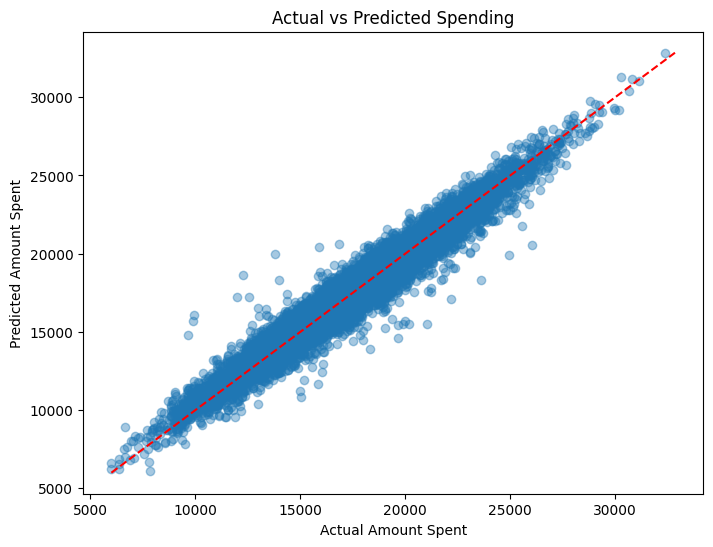

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Amount Spent")
plt.ylabel("Predicted Amount Spent")
plt.title("Actual vs Predicted Spending")

plt.show()

Descision Tree

In [8]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Results")
print("MAE:", mean_absolute_error(y_test, dt_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, dt_pred)))
print("R2:", r2_score(y_test, dt_pred))

print("Training R2:", dt_model.score(X_train, y_train))
print("Testing R2:", dt_model.score(X_test, y_test))


Decision Tree Results
MAE: 1130.049365
RMSE: 1442.0010458471206
R2: 0.8522797276188461
Training R2: 0.9999996591385207
Testing R2: 0.8522797276188461


Randomnized search cv

In [10]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [5, 8, 10, 12, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10, 20, 30],
    "min_samples_leaf": [1, 2, 4, 6, 10],
    "max_features": [None, "sqrt", 0.8],
    "criterion": ["squared_error", "friedman_mse", "absolute_error"]
}

dt_search = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_grid,
    n_iter=30,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

dt_search.fit(X_train, y_train)

best_dt = dt_search.best_estimator_

print("Best Parameters:", dt_search.best_params_)
print("Best CV RMSE:", -dt_search.best_score_)

# Predictions
dt_tuned_pred = best_dt.predict(X_test)

print("\nTuned Decision Tree Results")

print("MAE:", mean_absolute_error(y_test, dt_tuned_pred))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, dt_tuned_pred)
))

print("R2:", r2_score(y_test, dt_tuned_pred))

print("Training R2:", best_dt.score(X_train, y_train))
print("Testing R2:", best_dt.score(X_test, y_test))


Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters: {'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': None, 'max_depth': 15, 'criterion': 'squared_error'}
Best CV RMSE: 1282.1728604565985

Tuned Decision Tree Results
MAE: 966.6928134967931
RMSE: 1237.5218404113104
R2: 0.8912035577637272
Training R2: 0.9362703191598072
Testing R2: 0.8912035577637272


Random Forest Regressor

In [11]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [100, 150, 200, 300],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.8]
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_params,
    n_iter=15,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_

print("Best Parameters:", rf_search.best_params_)
print("Best CV RMSE:", -rf_search.best_score_)

rf_pred = best_rf.predict(X_test)

print("\nRandom Forest Results")

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2:", r2_score(y_test, rf_pred))

print("Training R2:", best_rf.score(X_train, y_train))
print("Testing R2:", best_rf.score(X_test, y_test))


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 25}
Best CV RMSE: 1004.1359143537569

Random Forest Results
MAE: 758.3130873088257
RMSE: 981.2599458804942
R2: 0.9315966939453263
Training R2: 0.9813215397133993
Testing R2: 0.9315966939453263
